# 05. Engagement

**Goal**: See when users respond to notifications, and check **whether the situations with more responses are the ones where steps increase**. This extends the "engagement is not the effect" finding from section 3.3 of 02 to all context variables and to time in the study.
**Why it matters**: Apps usually measure notification success by engagement (taps, feedback) because it is easy to measure. If engagement moves differently from actual behavior change (steps), optimizing for engagement could move away from what helps health behavior.

**Questions**
1. What do responses look like, and how much do people differ?
2. What is the engagement rate in each situation?
3. Are high-engagement situations the ones with large step effects?
4. Do engagement and the effect decline together over the study?
5. If people walked more after notifications they responded to, was that because of the notification?

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)

# This notebook lives in notebooks/, so the project folder is one level up.
PROJECT_DIR = Path("..")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BLUE = "#2a78d6"
GREY = "#9a9893"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

decision_points = pd.read_csv(PROCESSED_DIR / "decision_points.csv")
print(decision_points.shape)

(8274, 31)


### 0.1. Analysis sample

Build the same sample and context variables as in 04, and add the study week (`week`, as in 02).
- **Engagement sample (`engage`)**: notification sent and response recorded (as in section 3 of 02) -> sections 1-2
- **Walking engagement sample (`engage_walk`)**: walking notifications in `engage` → sections 3-5. The effects in 04 are for walking notifications, so the same type is compared.
- **Walking vs none (`walk_vs_none`)**: as in 04, used for the step effects.

In [2]:
sample = decision_points[(decision_points["available"] == 1) & (decision_points["travel_day"] == 0)].copy() # 가용O, 여행X

sample["slot_label"] = sample["slot"].astype(str) + " " + sample["slot_name"]
sample["day_type"] = sample["is_weekend"].map({0: "weekday", 1: "weekend"})
sample["phone_in_use"] = sample["screen_on"].map({0: "not in use", 1: "in use"})
sample["week"] = (sample["study_week"].clip(upper=5) + 1).astype(int)   # 6 = week 6 and later
sample["active"] = (sample["send_type"] == "active").astype(int)

engage = sample[(sample["sent"] == 1) & sample["engaged"].notna()]
engage_walk = engage[engage["send_type"] == "active"]
walk_vs_none = sample[sample["send_type"].isin(["active", "none"])]

print(f"Engagement sample: {len(engage)} notifications")
print(f"Walking notifications with a response record: {len(engage_walk)}")
print(f"Walking vs none: {len(walk_vs_none)} rows")

Engagement sample: 2909 notifications
Walking notifications with a response record: 1616
Walking vs none: 4675 rows


### 0.2. Functions

`fit_gee` and `effect_by_group` are the same as in 04. Sections 3 and 4 use them for the effect of walking notifications by context and by week.

In [3]:
# 결과변수 고정
OUTCOME = "log_steps_post30_zero"
PRE = "log_steps_pre30_zero"


def fit_gee(formula, data):
    model = smf.gee(
        formula,
        groups="user_id",                         # standard errors per participant
        data=data,
        cov_struct=sm.cov_struct.Independence(),
        missing="drop",                           # skip rows with a missing value in the formula
    )
    result = model.fit(cov_type="bias_reduced")   # small-sample correction
    ci = result.conf_int()
    table = pd.DataFrame({
        "estimate": result.params,
        "std_err": result.bse,
        "p_value": result.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    })
    return table.round(3)


def effect_by_group(data, context, treatment, outcome=OUTCOME, pre=PRE):
    rows = []
    for group, subset in data.groupby(context):           # rows with a missing context are skipped
        table = fit_gee(f"{outcome} ~ {pre} + {treatment}", subset)
        rows.append({
            "context": context,
            "group": group,
            "n_rows": len(subset),
            "participants": subset["user_id"].nunique(),
            "estimate": table.loc[treatment, "estimate"],
            "p_value": table.loc[treatment, "p_value"],
            "ci_low": table.loc[treatment, "ci_low"],
            "ci_high": table.loc[treatment, "ci_high"],
        })
    result = pd.DataFrame(rows)
    for col in ["estimate", "ci_low", "ci_high"]:
        result[f"{col}_pct"] = ((np.exp(result[col]) - 1) * 100).round(1)
    return result

---

## 1. What responses look like
Count the response values among sent notifications. `engaged` is 1 for good, bad, or snoozed and 0 for no response (section 5.5 of 01). Notifications with no response record are not in `engage` (section 4 of 02).

In [4]:
# 알림을 보낸 시점의 반응 구성
sent = sample[sample["sent"] == 1]
print(sent["response"].value_counts(dropna=False))
print()
print(f"Engagement rate: {engage['engaged'].mean():.3f}")
print(f"Share of 'good' among responses: {(engage['response'] == 'good').sum() / engage['engaged'].sum():.3f}")

response
good           1411
no_response     916
NaN             846
bad             551
snoozed          31
Name: count, dtype: int64

Engagement rate: 0.685
Share of 'good' among responses: 0.708


In [5]:
# 반응율
user_rate = engage.groupby("user_id")["engaged"].mean()
user_rate.describe().round(2)

count    37.00
mean      0.67
std       0.19
min       0.25
25%       0.53
50%       0.69
75%       0.85
max       0.93
Name: engaged, dtype: float64

- The engagement rate is 68.5%. About 71% of responses are "good"; most of the rest are "bad". -> **A response is not necessarily a positive one.**
- Engagement ranges from 25% to 93% across participants (section 3.1 of 02), so a group's rate can depend on which participants it contains.

---

## 2. Engagement rate by context
For the context variables of 04 plus notification type (`send_type`), compute the engagement rate and the share of notifications answered "good" (`good_rate`).

In [6]:
# 상황 변수, 알림 종류마다 반응률과 좋아요 비율

CONTEXTS = ["slot_label", "day_type", "location", "weather_group", "phone_in_use"]

engage = engage.assign(good=(engage["response"] == "good").astype(int))

for context in CONTEXTS + ["send_type"]:
    print(engage.groupby(context).agg(
        engagement_rate=("engaged", "mean"),
        good_rate=("good", "mean"),
        n=("engaged", "size"),
    ).round(3))
    print()

                   engagement_rate  good_rate    n
slot_label                                        
1 morning commute            0.566      0.362  640
2 lunch                      0.696      0.516  546
3 mid-afternoon              0.758      0.560  598
4 evening commute            0.716      0.530  553
5 after dinner               0.703      0.470  572

          engagement_rate  good_rate     n
day_type                                  
weekday             0.701      0.508  2053
weekend             0.647      0.431   856

          engagement_rate  good_rate     n
location                                  
home                0.644      0.454   787
other               0.673      0.466  1604
work                0.786      0.595   487

               engagement_rate  good_rate     n
weather_group                                  
clear                    0.703      0.493   988
cloudy                   0.675      0.475  1732
precipitation            0.671      0.537   149

            

- Engagement is highest **while the phone is in use** (85.9% vs 64.7%), probably because the notification is seen right away.
- Work (78.6%) and mid-afternoon (75.8%) are also high; the morning commute (56.6%) is the lowest.
- Walking and anti-sedentary notifications have almost the same engagement (68.9% vs 68.1%), although their step effects differed greatly in 03 (+23.5% vs +2.9%). → **Engagement and the effect diverge across notification types too.**
- The `unknown` value of `send_type` (1 notification) has no recorded type and is ignored.

---

## 3. Engagement compared with the step effect

- For walking notifications only, put each situation's engagement rate (`engage_walk`) next to its step effect (computed as in section 2 of 04). 
- If engagement were a good stand-in for the effect, situations with higher engagement should show larger effects.

In [7]:
# 효과
effects = pd.concat(
    [effect_by_group(walk_vs_none, context, "active") for context in CONTEXTS],
    ignore_index=True,
)

# 반응
rates = pd.concat(
    [engage_walk.groupby(context)["engaged"].mean().rename_axis("group").reset_index().assign(context=context)
     for context in CONTEXTS],
    ignore_index=True,
).rename(columns={"engaged": "engagement_rate"})

compare = rates.merge(effects[["context", "group", "estimate_pct", "p_value"]], on=["context", "group"])
compare["engagement_rate"] = compare["engagement_rate"].round(3)
compare[["context", "group", "engagement_rate", "estimate_pct", "p_value"]]

,context,group,engagement_rate,estimate_pct,p_value
0,slot_label,1 morning commute,0.589,-1.1,0.943
1,slot_label,2 lunch,0.681,75.6,0.002
2,slot_label,3 mid-afternoon,0.767,24.1,0.318
3,slot_label,4 evening commute,0.711,20.4,0.285
4,slot_label,5 after dinner,0.712,29.3,0.160
5,day_type,weekday,0.702,31.5,0.004
6,day_type,weekend,0.657,9.0,0.563
7,location,home,0.643,41.9,0.009
8,location,other,0.673,5.1,0.621
9,location,work,0.808,65.5,0.087


Rank correlation between engagement and effect: 0.25


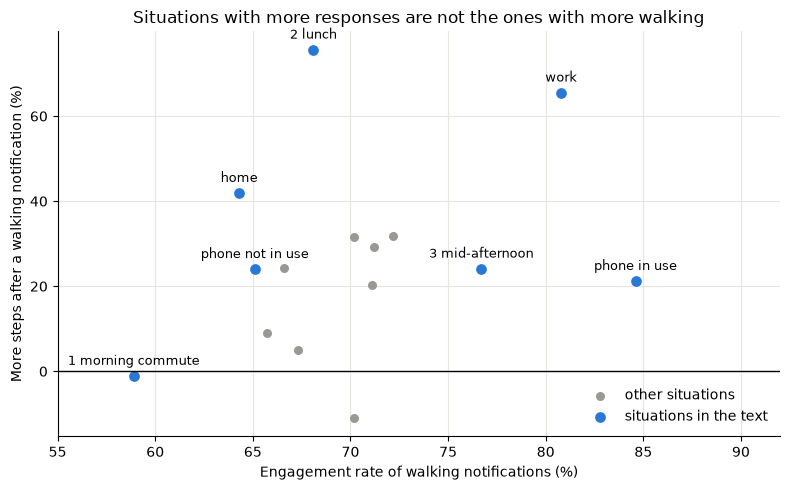

In [9]:
print(f"Rank correlation between engagement and effect: {compare['engagement_rate'].corr(compare['estimate_pct'], method='spearman'):.2f}")

# Readable names for the two phone-use groups
compare["label"] = compare["group"].replace({"in use": "phone in use", "not in use": "phone not in use"})

# Situations discussed in the text get a blue dot and a label; the rest stay grey
KEY = ["1 morning commute", "2 lunch", "3 mid-afternoon", "home", "work", "phone in use", "phone not in use"]
key = compare[compare["label"].isin(KEY)]
rest = compare[~compare["label"].isin(KEY)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(rest["engagement_rate"] * 100, rest["estimate_pct"], color=GREY, s=30, label="other situations")
ax.scatter(key["engagement_rate"] * 100, key["estimate_pct"], color=BLUE, s=45, label="situations in the text")
for _, row in key.iterrows():
    ax.annotate(row["label"], (row["engagement_rate"] * 100, row["estimate_pct"]),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)   # label centered above the dot
ax.axhline(0, color="black", linewidth=1)
ax.set_xlim(55, 92)
ax.set_xlabel("Engagement rate of walking notifications (%)")
ax.set_ylabel("More steps after a walking notification (%)")
ax.set_title("Situations with more responses are not the ones with more walking")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

- The rank correlation between engagement and the effect is weak (0.25); engagement says little about the effect.
- **Phone in use**: the highest engagement (84.6%), but the same effect as not in use (+21.2% vs +24.0%). Users see the notification more, but do not walk more.
- **Lunch**: engagement is on the low side (68.1%, 4th of 5 slots) but the effect is the largest (+75.6%). **Mid-afternoon** has the highest engagement (76.7%) but a +24.1% effect.
- **Home**: the lowest engagement among locations (64.3%) but a larger effect (+41.9%) than elsewhere (+5.1%).
- The points mix different context variables, and the differences in effect were not statistically confirmed (section 3 of 04), so the chart shows a pattern rather than a test.

---

## 4. Change over the study
In 03 the effect was large early in the study and gone after about 4 weeks. If engagement fell too, it could signal the decline. Compare engagement and the effect of walking notifications by week.

In [10]:
weekly_effect = effect_by_group(walk_vs_none, "week", "active").set_index("group")
weekly = pd.DataFrame({
    "engagement_rate": engage_walk.groupby("week")["engaged"].mean().round(3),
    "effect_pct": weekly_effect["estimate_pct"],
    "effect_p": weekly_effect["p_value"],
})
weekly

,engagement_rate,effect_pct,effect_p
1,0.742,131.4,0.000
2,0.676,31.4,0.179
3,0.681,11.3,0.604
4,0.635,54.7,0.037
5,0.720,-13.5,0.591
6,0.679,-4.2,0.821


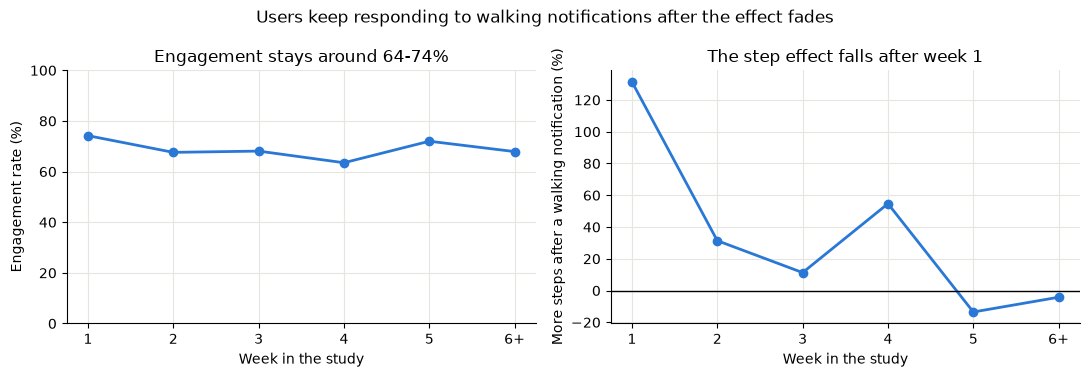

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
week_labels = [str(w) if w < 6 else "6+" for w in weekly.index]

axes[0].plot(weekly.index, weekly["engagement_rate"] * 100, marker="o", color=BLUE, linewidth=2)
axes[0].set(ylim=(0, 100), title="Engagement stays around 64-74%", xlabel="Week in the study", ylabel="Engagement rate (%)")

axes[1].plot(weekly.index, weekly["effect_pct"], marker="o", color=BLUE, linewidth=2)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="The step effect falls after week 1", xlabel="Week in the study", ylabel="More steps after a walking notification (%)")

for ax in axes:
    ax.set_xticks(weekly.index)
    ax.set_xticklabels(week_labels)
fig.suptitle("Users keep responding to walking notifications after the effect fades")
plt.tight_layout()
plt.show()

- Engagement barely changes, from 74.2% in week 1 to 67.9% in week 6 and later.
- The effect falls from +131.4% in week 1 (p < 0.001) to -13.5% in week 5 and -4.2% from week 6. It goes up and down (week 4: +54.7%, p = 0.037), but the trend matches section 2 of 03.
- -> Users keep responding after the effect is gone. **Judged by engagement alone, the notifications would seem to still work.**

---

## 5. Responses and steps
- It is tempting to think "steps are higher after notifications marked good, so more responses are better". 
- Split walking notifications by response and look at median steps **before** and **after** (medians, because step counts are skewed).

In [12]:
engage_walk.groupby("response").agg(
    steps_before=("steps_pre30_zero", "median"),
    steps_after=("steps_post30_zero", "median"),
    n=("engaged", "size"),
)

,steps_before,steps_after,n
response,,,
bad,33.5,42.0,378
good,58.0,88.0,717
no_response,28.0,26.0,503
snoozed,34.5,33.5,18


- Steps after a "good" response are the highest (median 88), but **so are steps before** (58 vs 28 for no response). People tend to answer "good" when they are already moving.
- The response happens **after** the notification and is not randomized, so comparisons by response are not effects of the notification. The effect requires comparing sent with not sent (03, 04).
- For the same reason, the response cannot be used like the context variables of 04 to choose when to send (data leakage).

---

## 6. Summary
| 비교 / Comparison | 반응률 / Engagement | 걸음 수 효과 / Step effect | 의미 / Meaning |
| --- | --- | --- | --- |
| 휴대폰 사용 중 vs 안 함 / Phone in use vs not | 84.6% vs 65.1% | +21.2% vs +24.0% | 알림을 더 볼 뿐 더 걷지는 않음 / Seen more, not walked more |
| 점심 vs 오후 중반 / Lunch vs mid-afternoon | 68.1% vs 76.7% | +75.6% vs +24.1% | 반응이 낮은 시간대의 효과가 더 큼 / Lower engagement, larger effect |
| 걷기 vs 앉아 있기 줄이기 / Walking vs anti-sedentary | 68.9% vs 68.1% | +23.5% vs +2.9% (03) | 반응은 같고 효과는 다름 / Same engagement, different effect |
| 1주차 vs 6주차 이후 / Week 1 vs week 6+ | 74.2% vs 67.9% | +131.4% vs −4.2% | 효과가 사라져도 반응은 유지 / Engagement stays after the effect fades |

**Conclusion**
- Engagement cannot stand in for the step effect; the two move differently across situations, notification types, and time.
- Notification success should be measured as the **difference in behavior between sent and not sent**, which needs a design that randomly withholds some notifications (a holdout), as in this study.

**Limitations**
- Engagement rates by context are simple averages and do not account for the large differences between participants (25-93%).
- Notifications with no response record (22.5% of sent) are left out (section 4 of 02).

**Next**: 07 proposes notification timing and frequency based on the step effect, not engagement.